# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
# Generating two pairs of numbers without set_seed()
numbers = list(range(10))
rand_num1 = random.randint(1, 100);
random.shuffle(numbers)
print(r"First pair of random nums:", rand_num1, numbers)

numbers = list(range(10))
rand_num2 = random.randint(1, 100);
random.shuffle(numbers)
print(r"Second pair of random nums:", rand_num2, numbers)

# Generating two pairs of numbers with 1 set_seed() before each generation
set_seed()
print("Seed зафіксовано:", SEED)
numbers = list(range(10))
rand_num3 = random.randint(1, 100);
random.shuffle(numbers)
print(r"Third pair of random nums:", rand_num3, numbers)

set_seed()
print("Seed зафіксовано:", SEED)
numbers = list(range(10))
rand_num4 = random.randint(1, 100);
random.shuffle(numbers)
print(r"Fourth pair of random nums:", rand_num4, numbers)


# Generating two pairs of numbers after 1 set_seed()
set_seed()
print("Seed зафіксовано:", SEED)

numbers = list(range(10))
rand_num9 = random.randint(1, 100);
random.shuffle(numbers)
print(r"Fifth pair of random nums:", rand_num9, numbers)
rand_num11 = random.randint(1, 100);
random.shuffle(numbers)
print(r"Sixth pair of random nums:", rand_num11, numbers)


First pair of random nums: 82 [5, 8, 0, 2, 4, 6, 9, 7, 1, 3]
Second pair of random nums: 24 [3, 2, 0, 7, 9, 8, 4, 5, 6, 1]
Seed зафіксовано: 42
Third pair of random nums: 82 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Seed зафіксовано: 42
Fourth pair of random nums: 82 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Seed зафіксовано: 42
Fifth pair of random nums: 82 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Sixth pair of random nums: 76 [5, 8, 2, 1, 6, 3, 4, 0, 7, 9]


## Пояснення до вправи 1
Оскільки комп'ютер не вміє генерувати дійсно випадкові числа, тому використовуються детерміністичні методи для генерації псевдо випадкових чисел. По факту такі згенеровані числа можна передбачити якщо відоме зерно та параметри які були використані для генерації.

Це ми і бачимо у вправі:
- Під час генерації перших двох пар псевдо випадкових чисел ми бачимо різні значення.
- Під час генерації наступних двох пар ми бачимо однакові значення оскільки ми встановлюємо зерно перед кожною та отримуємо перше випадкове число, яке при однакових зернах є однакове.
- Під час генерації останніх двох пар ми бачимо різні значення оскільки генеруються перше та наступне псевдо випадкові числа.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [7]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [8]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [9]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [10]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [11]:
arr = np.arange(1, 13)

matrix = np.reshape(arr, (3, 4))
row_sums = np.sum(matrix, 1)
col_sums = np.sum(matrix, 0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [12]:
data = {
    "Name": ["John Doe", "Ed Sheeran", "Fil Spenser", "Barak Obama", "Hunter Biden"],
    "Score": [81, 65, 93, 48, 76]
}
df = pd.DataFrame(data)


top = df[df["Score"] > 80].sort_values(by="Score", ascending=False);
print(top)


          Name  Score
2  Fil Spenser     93
0     John Doe     81


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [13]:
df["grade"] = df["Score"].apply(lambda x: "A" if x >= 90 else "B" if x >= 74 else "C")
print(df)


           Name  Score grade
0      John Doe     81     B
1    Ed Sheeran     65     C
2   Fil Spenser     93     A
3   Barak Obama     48     C
4  Hunter Biden     76     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [14]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2,3), 7)

print(zeros_t)
print(sevens_t)


tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[7, 7, 7],
        [7, 7, 7]])


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [15]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [16]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print(random_t)


tensor([[1, 2],
        [3, 4]])
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [17]:
n = 5.0
x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()
print("Calculated grad: ", x.grad.item(), ", Real: ", 2 * n)


Calculated grad:  10.0 , Real:  10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [18]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for i in range(20):
  loss = (x - 3) ** 2 + 5
  loss.backward()

  with torch.no_grad():
    x -= lr * x.grad
    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

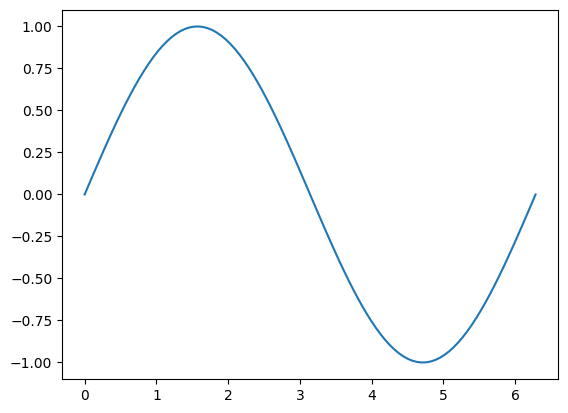

In [19]:
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

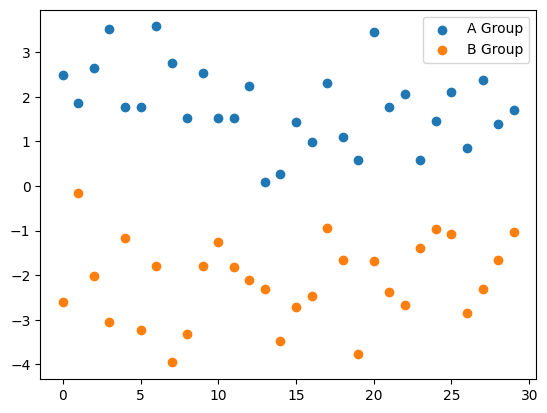

In [20]:
set_seed()
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),

plt.scatter(np.arange(30), group_a, color="C0", label="A Group")
plt.scatter(np.arange(30), group_b, color="C1", label="B Group")

plt.legend(),
plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [21]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

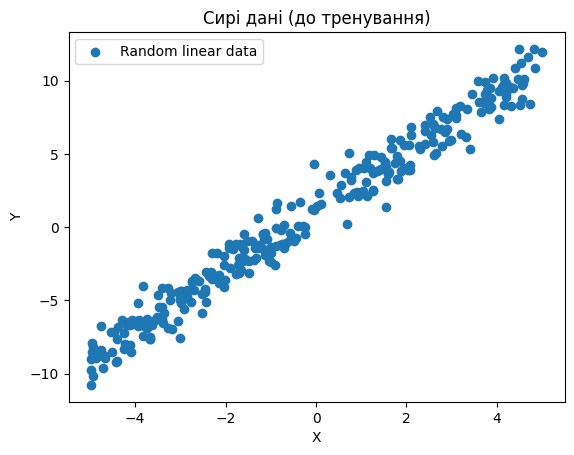

In [22]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок


plt.scatter(x1, y1,  color="C0", label="Random linear data")
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Сирі дані (до тренування)")
plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [23]:
rnd_indices = torch.randperm(TASK1_N)
train_size = int(0.7 * TASK1_N)
val_size = int(0.15 * TASK1_N)
test_size = TASK1_N - train_size - val_size;

train_idx = rnd_indices[:train_size]
val_idx = rnd_indices[train_size : train_size + val_size]
test_idx = rnd_indices[train_size + val_size:]

x_train1, y_train1 = x1[train_idx], y1[train_idx]
x_val1, y_val1 = x1[val_idx], y1[val_idx]
x_test1, y_test1 = x1[test_idx], y1[test_idx]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [24]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=52.999176  w=1.7073 (true 2.0)  b=-0.1046 (true 1.0)
epoch   30  loss=0.873840  w=2.0204 (true 2.0)  b=0.9961 (true 1.0)
epoch   60  loss=0.870761  w=2.0217 (true 2.0)  b=1.0441 (true 1.0)
epoch   90  loss=0.870755  w=2.0218 (true 2.0)  b=1.0462 (true 1.0)
epoch   99  loss=0.870755  w=2.0218 (true 2.0)  b=1.0462 (true 1.0)


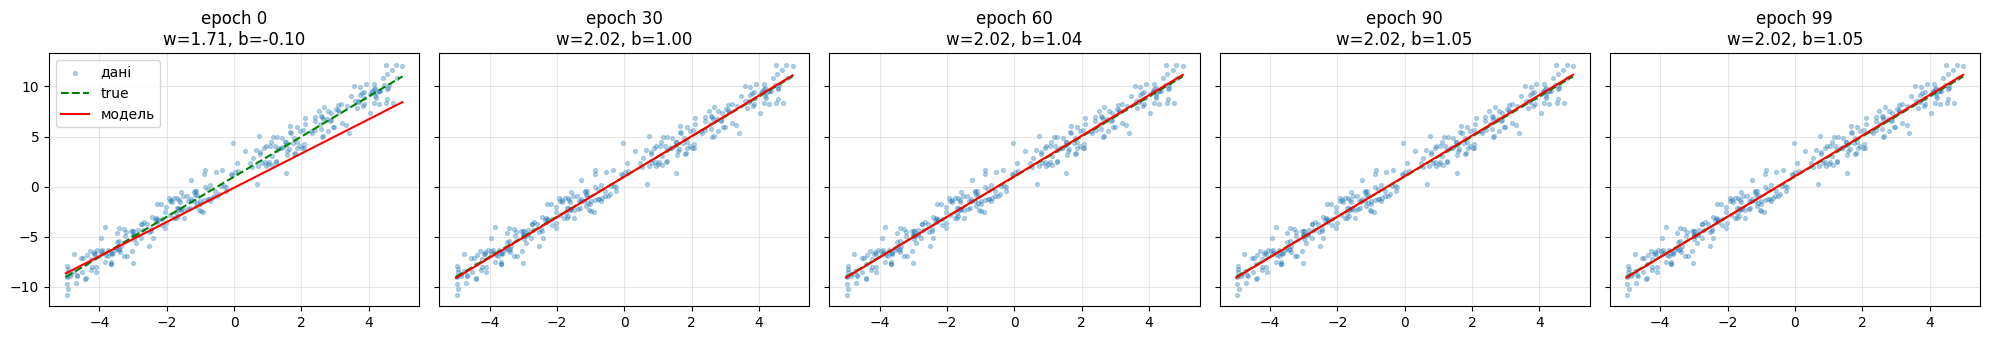

In [25]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

# Опис моделі
Було обрано залежність: Вік автомобіля (роки) -> Середні річні витрати на позаплановий ремонт (тис. грн)

Досліджуємо залежність річних витрат автовласника на усунення непередбачених поломок та заміну зношених деталей від віку машини в роках. Регулярне базове обслуговування сюди не входить.


# Параметри лінійної моделі ($y = w \cdot x + b$)
$w = 3.0$: Кожен додатковий рік експлуатації додає в середньому близько 3 000 грн до очікуваного річного чеку на ремонти. З віком накопичується втома металу, розсихаються гумові вироби, а ресурс складних вузлів поступово вичерпується, тому витрати на дрібні і середні ремонти зростає.

$b = 2.0$: Витрати для майже нового автомобіля ($x = 0$ років) становлять близько 2 000 грн. Навіть у гарантійний період існує ймовірність пробити колесо, подерти фарбу, чи зіткнутися з іншою негарантійною дрібницею.

## Генеруємо випадкові дані

In [26]:
set_seed(69)

MODEL_TRUE_W = 3.0
MODEL_TRUE_B = 2.0
MODEL_N = 300

x = torch.empty(MODEL_N, 1).uniform_(0, 10)
noise = 1.0 * torch.randn(MODEL_N, 1)
y = MODEL_TRUE_W * x + MODEL_TRUE_B + noise

## Збережемо сирі дані

In [27]:
df = pd.DataFrame({
    "x": x.squeeze().numpy(),
    "y": y.squeeze().numpy()
})
FILE_PATH = ARTIFACT_DIR + "/dataset.csv"
df.to_csv(FILE_PATH, index=False)

## Візуалізуємо Сирі дані

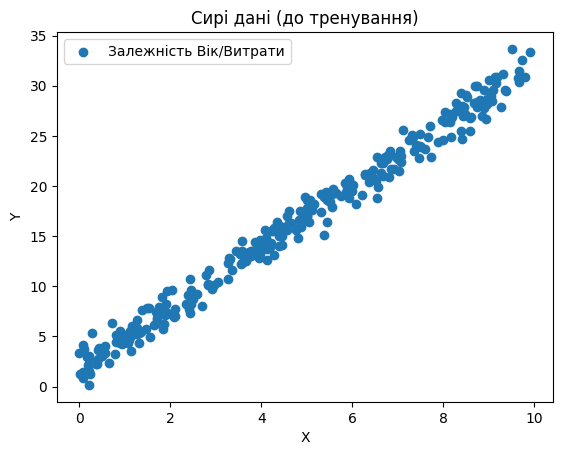

In [28]:
plt.scatter(x, y,  color="C0", label="Залежність Вік/Витрати")
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Сирі дані (до тренування)")
plt.show()

## Розбиваємо дані (train, val, test)

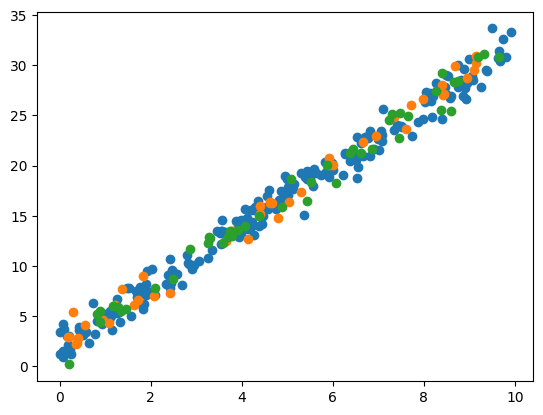

train/val/test: 210/45/45


In [29]:
rnd_indices = torch.randperm(MODEL_N)
train_size = int(0.7 * MODEL_N)
val_size = int(0.15 * MODEL_N)
test_size = MODEL_N - train_size - val_size;

train_idx = rnd_indices[:train_size]
val_idx = rnd_indices[train_size : train_size + val_size]
test_idx = rnd_indices[train_size + val_size:]

x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]
x_test, y_test = x[test_idx], y[test_idx]

plt.scatter(x_train, y_train,  color="C0", label="y_train")
plt.scatter(x_val, y_val,  color="C1", label="y_val")
plt.scatter(x_test, y_test,  color="C2", label="y_test")
plt.show()

print(f"train/val/test: {len(x_train)}/{len(x_val)}/{len(x_test)}")

## Створюємо та тренуємо модель

In [30]:
set_seed(69)

model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(0, 10, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = model(x_train)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = model(x_line)
        snapshots.append((epoch, model.weight.item(), model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={model.weight.item():.4f} (true {MODEL_TRUE_W})  "
              f"b={model.bias.item():.4f} (true {MODEL_TRUE_B})")


epoch    0  loss=194.644226  w=2.2042 (true 3.0)  b=0.8533 (true 2.0)
epoch   30  loss=1.236089  w=3.1314 (true 3.0)  b=1.1361 (true 2.0)
epoch   60  loss=1.191160  w=3.1135 (true 3.0)  b=1.2502 (true 2.0)
epoch   90  loss=1.158311  w=3.0981 (true 3.0)  b=1.3478 (true 2.0)
epoch   99  loss=1.150300  w=3.0939 (true 3.0)  b=1.3742 (true 2.0)


## Візуалізуємо навчання

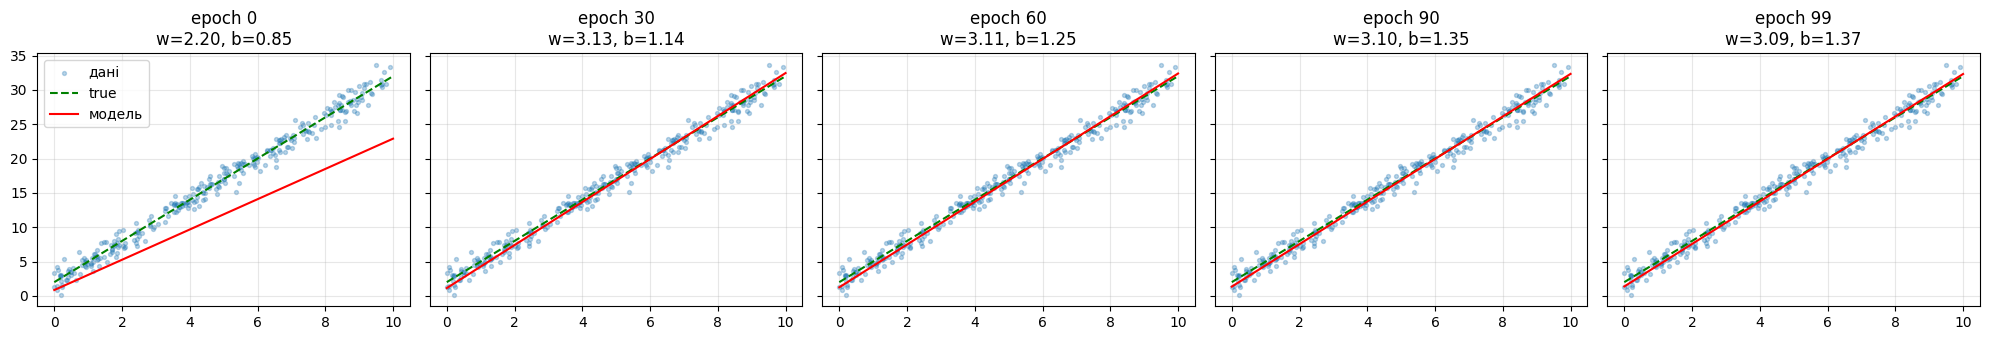

In [31]:
with torch.no_grad():
    y_line_true = MODEL_TRUE_W * x_line + MODEL_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x.numpy(), y.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [32]:
MODEL_FILE = ARTIFACT_DIR + "/model.pt"
torch.save(model.state_dict(), MODEL_FILE)

**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [33]:
!pip install -q gradio
import gradio as gr

In [34]:
model = torch.nn.Linear(in_features=1, out_features=1)

model.load_state_dict(torch.load(MODEL_FILE))
model.eval()

def predict(x_val):
    tensor = torch.tensor([[float(x_val)]], dtype=torch.float32)

    with torch.no_grad():
        prediction = model(tensor)

    return round(prediction.item(), 4)

demo = gr.Interface(
    fn=predict,
    inputs=gr.Number(
        label="Вік авто (X)",
        value=5.0,
        info="Введіть число для прогнозу",
    ),
    outputs=gr.Number(label="Прогнозовані річні витрати (Y) (тис. грн.)"),
    title="Інтерактивний прогноз позапланових витрат авто",
    examples=[[0.0], [2.0], [5.0], [10.0]],
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3bd24c428f23ab15aa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```